
# Manufacturing Quality & Operational Performance Analysis

### A Python-Based Manufacturing KPI and Quality Monitoring Project

## 1. Business Context

Manufacturing operations require reliable performance indicators
to monitor production efficiency, product quality, and operational
costs. Understanding these metrics can help teams identify
performance variations and prioritize further investigations.

## 2. Project Objective

This project aims to:

- Define and calculate manufacturing performance KPIs.
- Validate and explore manufacturing operational data.
- Investigate potential relationships between defect rates
  and operational factors.
- Develop a visual KPI dashboard.
- Identify quality-monitoring opportunities and propose
  data-informed operational recommendations.

## 3. Dataset

Source: Predicting Manufacturing Defects Dataset
(Kaggle, Rabie El Kharoua)

Dataset: 3,240 observations and 17 original variables.

The dataset contains synthetic manufacturing information
covering production, quality, maintenance, supplier performance,
and operational efficiency.

## 4. Tools

- Python
- pandas
- matplotlib
- Google Colab

## 5. Analytical Approach

Data Validation → KPI Definition → Exploratory Analysis →
Quality Investigation → Dashboard → Business Recommendations

**Important:** This project uses synthetic data.
Findings are illustrative and do not represent actual
FUJIFILM manufacturing operations.


In [70]:

import os

# Show the current working directory
print("Current folder:", os.getcwd())

# List files in the current folder
print("Files:", os.listdir())


Current folder: /content
Files: ['.config', 'manufacturing_defect_dataset (1).csv', 'downtime_vs_defect_rate.png', 'operational_group_comparison.png', 'manufacturing_kpi_dashboard.png', 'defect_rate_distribution.png', 'manufacturing_defect_dataset.csv', 'sample_data']


In [71]:

#from google.colab import files

#uploaded = files.upload()


In [72]:
import pandas as pd

df = pd.read_csv("manufacturing_defect_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (3240, 17)


In [73]:

import pandas as pd

# Load the manufacturing dataset
df = pd.read_csv("manufacturing_defect_dataset.csv")

# Display the first 5 rows
display(df.head())

# Check the dataset dimensions
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())


,ProductionVolume,ProductionCost,SupplierQuality,DeliveryDelay,DefectRate,QualityScore,MaintenanceHours,DowntimePercentage,InventoryTurnover,StockoutRate,WorkerProductivity,SafetyIncidents,EnergyConsumption,EnergyEfficiency,AdditiveProcessTime,AdditiveMaterialCost,DefectStatus
0,202,13175.403783,86.648534,1,3.121492,63.463494,9,0.052343,8.630515,0.081322,85.042379,0,2419.616785,0.468947,5.551639,236.439301,1
1,535,19770.046093,86.310664,4,0.819531,83.697818,20,4.908328,9.296598,0.038486,99.657443,7,3915.566713,0.119485,9.080754,353.957631,1
2,960,19060.820997,82.132472,0,4.514504,90.350550,1,2.464923,5.097486,0.002887,92.819264,2,3392.385362,0.496392,6.562827,396.189402,1
3,370,5647.606037,87.335966,5,0.638524,67.628690,8,4.692476,3.577616,0.055331,96.887013,8,4652.400275,0.183125,8.097496,164.135870,1
4,206,7472.222236,81.989893,3,3.867784,82.728334,9,2.746726,6.851709,0.068047,88.315554,7,1581.630332,0.263507,6.406154,365.708964,1


Dataset shape: (3240, 17)

Column names:
['ProductionVolume', 'ProductionCost', 'SupplierQuality', 'DeliveryDelay', 'DefectRate', 'QualityScore', 'MaintenanceHours', 'DowntimePercentage', 'InventoryTurnover', 'StockoutRate', 'WorkerProductivity', 'SafetyIncidents', 'EnergyConsumption', 'EnergyEfficiency', 'AdditiveProcessTime', 'AdditiveMaterialCost', 'DefectStatus']


In [74]:

# 1. Check column data types
print("DATA TYPES")
print(df.dtypes)

# 2. Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# 3. View summary statistics
print("\nSUMMARY STATISTICS")
display(df.describe().T)



DATA TYPES
ProductionVolume          int64
ProductionCost          float64
SupplierQuality         float64
DeliveryDelay             int64
DefectRate              float64
QualityScore            float64
MaintenanceHours          int64
DowntimePercentage      float64
InventoryTurnover       float64
StockoutRate            float64
WorkerProductivity      float64
SafetyIncidents           int64
EnergyConsumption       float64
EnergyEfficiency        float64
AdditiveProcessTime     float64
AdditiveMaterialCost    float64
DefectStatus              int64
dtype: object

MISSING VALUES
ProductionVolume        0
ProductionCost          0
SupplierQuality         0
DeliveryDelay           0
DefectRate              0
QualityScore            0
MaintenanceHours        0
DowntimePercentage      0
InventoryTurnover       0
StockoutRate            0
WorkerProductivity      0
SafetyIncidents         0
EnergyConsumption       0
EnergyEfficiency        0
AdditiveProcessTime     0
AdditiveMaterialCost    0

,count,mean,std,min,25%,50%,75%,max
ProductionVolume,3240.0,548.523148,262.402073,100.000000,322.000000,549.000000,775.250000,999.000000
ProductionCost,3240.0,12423.018476,4308.051904,5000.174521,8728.829280,12405.204656,16124.462428,19993.365549
SupplierQuality,3240.0,89.833290,5.759143,80.004820,84.869219,89.704861,94.789936,99.989214
DeliveryDelay,3240.0,2.558951,1.705804,0.000000,1.000000,3.000000,4.000000,5.000000
DefectRate,3240.0,2.749116,1.310154,0.500710,1.598033,2.708775,3.904533,4.998529
QualityScore,3240.0,80.134272,11.611750,60.010098,70.103420,80.265312,90.353822,99.996993
MaintenanceHours,3240.0,11.476543,6.872684,0.000000,5.750000,12.000000,17.000000,23.000000
DowntimePercentage,3240.0,2.501373,1.443684,0.001665,1.264597,2.465151,3.774861,4.997591
InventoryTurnover,3240.0,6.019662,2.329791,2.001611,3.983249,6.022389,8.050222,9.998577
StockoutRate,3240.0,0.050878,0.028797,0.000002,0.026200,0.051837,0.075473,0.099997


In [75]:

# Check for missing values
print("Total missing values:", df.isnull().sum().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check DefectStatus values
print("\nDefect status distribution:")
print(df["DefectStatus"].value_counts())

# Check data types
print("\nData types:")
print(df.dtypes)


Total missing values: 0
Duplicate rows: 0

Defect status distribution:
DefectStatus
1    2723
0     517
Name: count, dtype: int64

Data types:
ProductionVolume          int64
ProductionCost          float64
SupplierQuality         float64
DeliveryDelay             int64
DefectRate              float64
QualityScore            float64
MaintenanceHours          int64
DowntimePercentage      float64
InventoryTurnover       float64
StockoutRate            float64
WorkerProductivity      float64
SafetyIncidents           int64
EnergyConsumption       float64
EnergyEfficiency        float64
AdditiveProcessTime     float64
AdditiveMaterialCost    float64
DefectStatus              int64
dtype: object


In [76]:

# KPI 1: Average recorded defect rate
average_defect_rate = df["DefectRate"].mean()

print(f"Average Defect Rate: {average_defect_rate:.2f}")

# Compare with the median
median_defect_rate = df["DefectRate"].median()

print(f"Median Defect Rate: {median_defect_rate:.2f}")



Average Defect Rate: 2.75
Median Defect Rate: 2.71


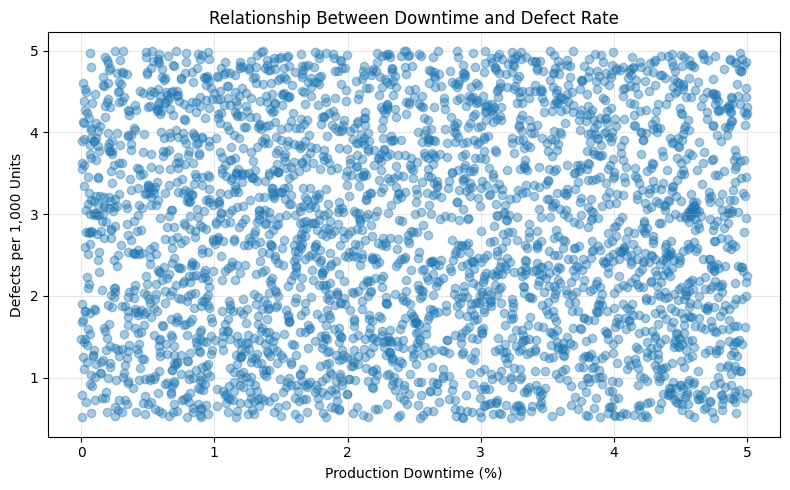

In [77]:


import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["DowntimePercentage"],
    df["DefectRate"],
    alpha=0.4
)

plt.xlabel("Production Downtime (%)")
plt.ylabel("Defects per 1,000 Units")
plt.title("Relationship Between Downtime and Defect Rate")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "downtime_vs_defect_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [78]:

# Calculate Pearson correlation
correlation = df["DowntimePercentage"].corr(
    df["DefectRate"]
)

print(f"Pearson correlation (r): {correlation:.4f}")


Pearson correlation (r): -0.0112


In [79]:

# Select manufacturing variables
variables = [
    "SupplierQuality",
    "MaintenanceHours",
    "DowntimePercentage",
    "WorkerProductivity",
    "ProductionVolume",
    "ProductionCost",
    "DeliveryDelay",
    "QualityScore"
]

# Calculate correlations with DefectRate
correlations = df[variables].corrwith(
    df["DefectRate"]
)

# Sort by strongest absolute correlation
correlations = correlations.reindex(
    correlations.abs().sort_values(ascending=False).index
)

print("Correlations with Defect Rate:")
display(correlations.round(4))


Correlations with Defect Rate:


,0
QualityScore,-0.0363
DeliveryDelay,-0.0230
ProductionVolume,-0.0194
ProductionCost,0.0144
SupplierQuality,0.0122
DowntimePercentage,-0.0112
MaintenanceHours,-0.0087
WorkerProductivity,-0.0004


In [80]:

# Check that production volumes are positive
print("Zero or negative production volumes:",
      (df["ProductionVolume"] <= 0).sum())

# Calculate cost per unit for each observation
df["CostPerUnit"] = (
    df["ProductionCost"] / df["ProductionVolume"]
)

# Calculate overall volume-weighted cost per unit
overall_cost_per_unit = (
    df["ProductionCost"].sum() /
    df["ProductionVolume"].sum()
)

print(f"Overall Cost Per Unit: {overall_cost_per_unit:.2f}")

# Show distribution of cost per unit
display(df["CostPerUnit"].describe())


Zero or negative production volumes: 0
Overall Cost Per Unit: 22.65


,CostPerUnit
count,3240.000000
mean,32.056882
std,27.097178
min,5.166510
25%,15.144584
50%,22.695831
75%,37.887605
max,199.577353


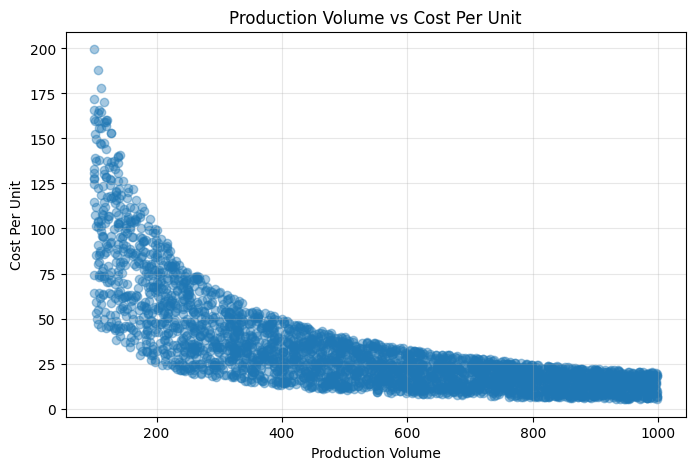

Pearson correlation: -0.7261


In [81]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["ProductionVolume"],
    df["CostPerUnit"],
    alpha=0.4
)

plt.xlabel("Production Volume")
plt.ylabel("Cost Per Unit")
plt.title("Production Volume vs Cost Per Unit")

plt.grid(alpha=0.3)
plt.show()

# Calculate correlation
correlation = df["ProductionVolume"].corr(
    df["CostPerUnit"]
)

print(f"Pearson correlation: {correlation:.4f}")


In [82]:

# Correlation between production volume and total cost
volume_cost_corr = df["ProductionVolume"].corr(
    df["ProductionCost"]
)

print(f"Volume vs Total Cost correlation: {volume_cost_corr:.4f}")

# Correlation between production volume and cost per unit
volume_unit_corr = df["ProductionVolume"].corr(
    df["CostPerUnit"]
)

print(f"Volume vs Cost Per Unit correlation: {volume_unit_corr:.4f}")


Volume vs Total Cost correlation: 0.0296
Volume vs Cost Per Unit correlation: -0.7261



## KPI Definition and Calculation Logic

The following KPIs were selected to monitor manufacturing quality, operational performance, and cost efficiency.

| KPI | Calculation | Business Purpose |
|---|---|---|
| Average Defects per 1,000 Units | Mean of DefectRate | Monitor typical recorded defect frequency |
| Average Downtime (%) | Mean of DowntimePercentage | Monitor production downtime |
| Overall Cost per Unit ($) | Sum of ProductionCost / Sum of ProductionVolume | Measure production cost per unit |
| Average Supplier Quality (%) | Mean of SupplierQuality | Monitor supplier quality performance |
| Average Worker Productivity (%) | Mean of WorkerProductivity | Monitor workforce productivity |
| Defect-Rate Threshold Exceedance (%) | Count of observations with DefectRate > 4.0 / Total observations × 100 | Identify observations requiring further quality investigation |

### KPI Interpretation and Assumptions

- **Defect Rate:** Measured as defects per 1,000 units produced. The dataset average is approximately 2.75 defects per 1,000 units.
- **Downtime:** Measured as a percentage of production downtime.
- **Production Cost:** Reported in USD ($). Overall cost per unit = Total Production Cost / Total Production Volume.
- **Quality and Productivity Scores:** SupplierQuality and WorkerProductivity are recorded as percentages.
- **Quality Monitoring Threshold:** A value above 4.0 defects per 1,000 units is flagged for investigation. This is an illustrative threshold, not an industry or FUJIFILM standard.
- **Threshold Exceedance:** 22.84% of observations exceeded the illustrative threshold. This is not the percentage of defective units produced.
- **Dataset:** Synthetic data created for educational purposes.


In [83]:

# Manufacturing KPI Summary

kpi_summary = pd.DataFrame({
    "KPI": [
        "Average Defects per 1,000 Units",
        "Average Downtime (%)",
        "Overall Cost per Unit ($)",
        "Average Supplier Quality (%)",
        "Average Worker Productivity (%)"
    ],
    "Value": [
        df["DefectRate"].mean(),
        df["DowntimePercentage"].mean(),
        df["ProductionCost"].sum() / df["ProductionVolume"].sum(),
        df["SupplierQuality"].mean(),
        df["WorkerProductivity"].mean()
    ]
})

# Round KPI values to two decimal places
kpi_summary["Value"] = kpi_summary["Value"].round(2)

# Display KPI summary table
display(kpi_summary)


,KPI,Value
0,"Average Defects per 1,000 Units",2.75
1,Average Downtime (%),2.50
2,Overall Cost per Unit ($),22.65
3,Average Supplier Quality (%),89.83
4,Average Worker Productivity (%),90.04


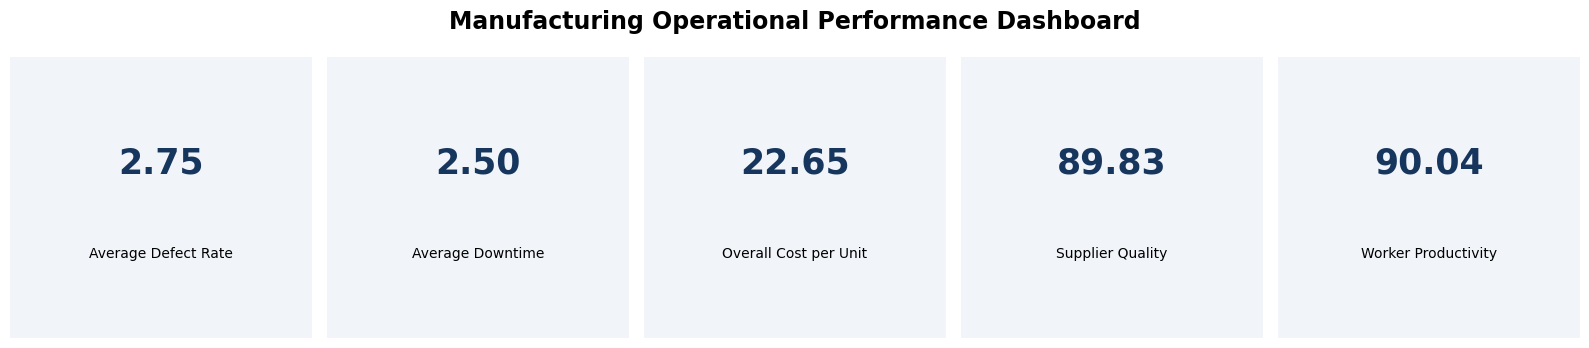

In [84]:

import matplotlib.pyplot as plt

kpis = [
    ("Average Defect Rate", 2.75),
    ("Average Downtime", 2.50),
    ("Overall Cost per Unit", 22.65),
    ("Supplier Quality", 89.83),
    ("Worker Productivity", 90.04)
]

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))

for ax, (name, value) in zip(axes, kpis):
    ax.set_facecolor("#F1F5F9")
    ax.text(
        0.5, 0.62, f"{value:.2f}",
        ha="center", va="center",
        fontsize=25, fontweight="bold",
        color="#17365D"
    )
    ax.text(
        0.5, 0.30, name,
        ha="center", va="center",
        fontsize=10, wrap=True
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    "Manufacturing Operational Performance Dashboard",
    fontsize=17, fontweight="bold"
)

plt.tight_layout()
plt.show()


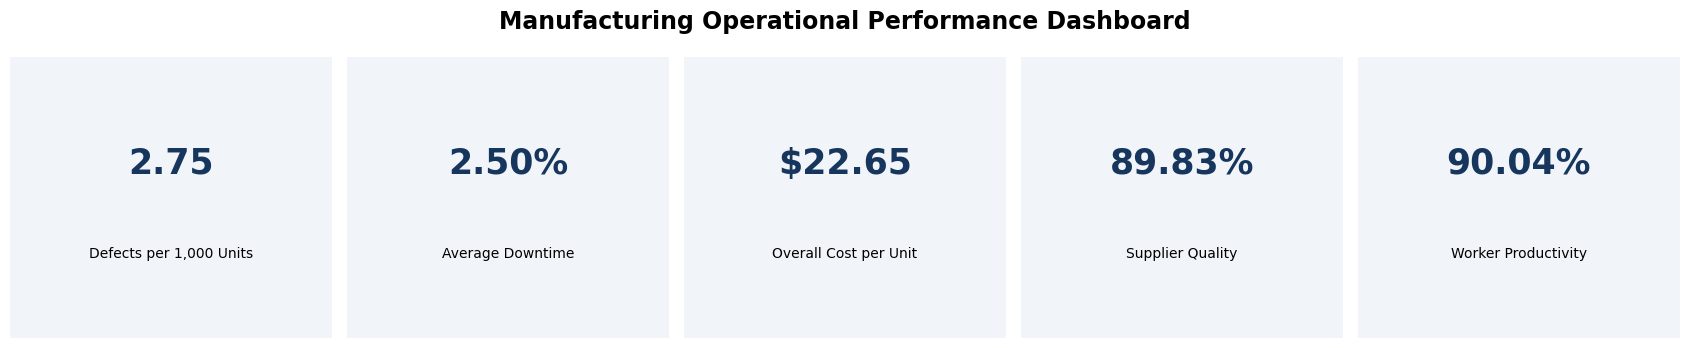

In [85]:

#updated version
import matplotlib.pyplot as plt

# Calculate manufacturing KPIs directly from the dataset
kpis = [
    ("Defects per 1,000 Units", df["DefectRate"].mean(), ""),
    ("Average Downtime", df["DowntimePercentage"].mean(), "%"),
    ("Overall Cost per Unit",
     df["ProductionCost"].sum() / df["ProductionVolume"].sum(), "$"),
    ("Supplier Quality", df["SupplierQuality"].mean(), "%"),
    ("Worker Productivity", df["WorkerProductivity"].mean(), "%")
]

# Create five KPI cards
fig, axes = plt.subplots(1, 5, figsize=(17, 3.5))

for ax, (name, value, unit) in zip(axes, kpis):
    ax.set_facecolor("#F1F5F9")

    # Format KPI value with the correct unit
    if unit == "$":
        formatted_value = f"${value:.2f}"
    else:
        formatted_value = f"{value:.2f}{unit}"

    ax.text(
        0.5, 0.62, formatted_value,
        ha="center", va="center",
        fontsize=25, fontweight="bold",
        color="#17365D"
    )

    ax.text(
        0.5, 0.30, name,
        ha="center", va="center",
        fontsize=10, wrap=True
    )

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    "Manufacturing Operational Performance Dashboard",
    fontsize=17, fontweight="bold"
)

plt.tight_layout()

# Save dashboard for GitHub portfolio
plt.savefig(
    "manufacturing_kpi_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


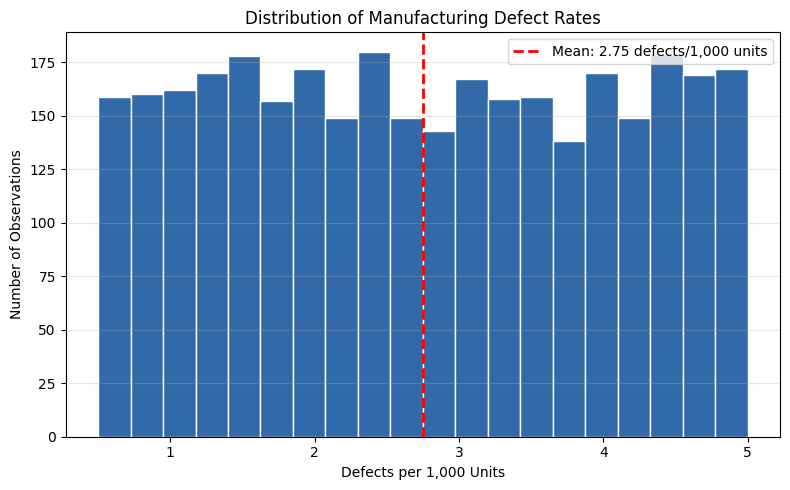

In [86]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    df["DefectRate"],
    bins=20,
    color="#3269A8",
    edgecolor="white"
)

# Add a reference line for the average defect rate
plt.axvline(
    df["DefectRate"].mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {df['DefectRate'].mean():.2f} defects/1,000 units"
)

plt.xlabel("Defects per 1,000 Units")
plt.ylabel("Number of Observations")
plt.title("Distribution of Manufacturing Defect Rates")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save chart for GitHub portfolio
plt.savefig(
    "defect_rate_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [87]:

# Define an illustrative high-defect threshold
threshold = 4.0

# Identify observations above the threshold
high_defect = df[df["DefectRate"] > threshold]

# Calculate number and percentage
high_defect_count = len(high_defect)
high_defect_pct = high_defect_count / len(df) * 100

print("High-defect observations:", high_defect_count)
print(f"Percentage of observations: {high_defect_pct:.2f}%")


High-defect observations: 740
Percentage of observations: 22.84%


In [88]:

# Create groups using our illustrative threshold
df["DefectGroup"] = df["DefectRate"].apply(
    lambda x: "High Defect" if x > 4.0 else "Other"
)

# Compare operational characteristics
comparison = df.groupby("DefectGroup")[
    [
        "SupplierQuality",
        "DowntimePercentage",
        "MaintenanceHours",
        "WorkerProductivity"
    ]
].mean().round(2)

display(comparison)


,SupplierQuality,DowntimePercentage,MaintenanceHours,WorkerProductivity
DefectGroup,,,,
High Defect,89.93,2.53,11.71,90.15
Other,89.80,2.49,11.41,90.01


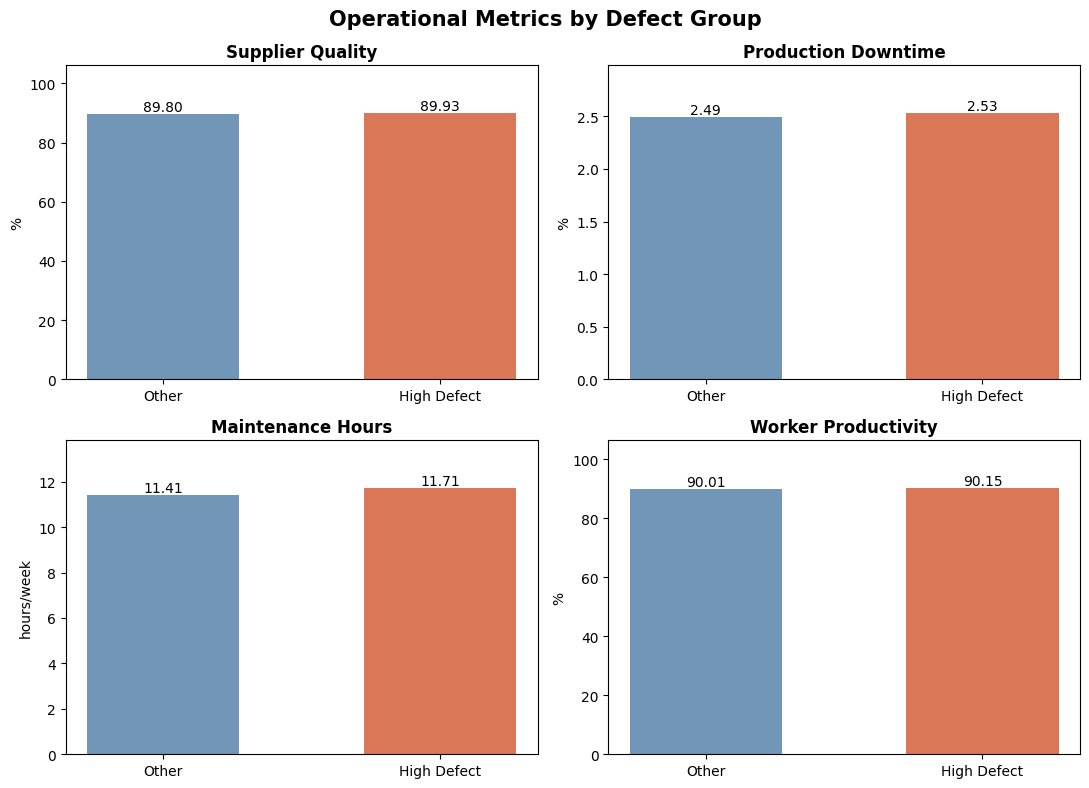

In [89]:

import matplotlib.pyplot as plt

metrics = {
    "SupplierQuality": ("Supplier Quality", "%"),
    "DowntimePercentage": ("Production Downtime", "%"),
    "MaintenanceHours": ("Maintenance Hours", "hours/week"),
    "WorkerProductivity": ("Worker Productivity", "%")
}

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, (metric, (title, unit)) in zip(
    axes.flatten(), metrics.items()
):
    values = comparison.loc[
        ["Other", "High Defect"], metric
    ]

    bars = ax.bar(
        ["Other", "High Defect"],
        values,
        color=["#7296B7", "#D97757"],
        width=0.55
    )

    ax.set_title(title, fontweight="bold")
    ax.set_ylabel(unit)
    ax.set_ylim(bottom=0, top=max(values) * 1.18)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.2f}",
            ha="center",
            va="bottom"
        )

fig.suptitle(
    "Operational Metrics by Defect Group",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "operational_group_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Key Findings and Business Recommendations

### Business Objective and Analytical Approach

Manufacturing teams rely on consistent operational KPIs to monitor quality, identify performance deviations, and prioritise investigations.

This project uses a synthetic manufacturing dataset containing 3,240 observations to explore three business questions:

1. What is the overall manufacturing quality and operational performance?
2. Are higher defect rates associated with supplier quality, downtime, maintenance, or other operational factors?
3. What can production volume and cost data tell us about operational efficiency?

Using Python and pandas, I validated the dataset, defined and calculated manufacturing KPIs, created visualisations, examined Pearson correlations, and compared operational metrics across defect-rate groups.

The objective was to translate analytical results into practical recommendations while recognising the limitations of the available data.

### 1. Manufacturing Quality Performance

**What was analysed**

I calculated the average recorded defect rate, examined its distribution, and applied an illustrative threshold of more than 4 defects per 1,000 units to identify observations for further review.

**Key findings**

- The average recorded defect rate was **2.75 defects per 1,000 units**.
- **740 of 3,240 observations (22.84%)** exceeded the illustrative threshold. This percentage represents flagged observations, not the percentage of defective products.
- Recorded defect rates were distributed relatively evenly across the observed range.

**Business recommendation**

Introduce threshold-based quality monitoring to flag observations for investigation. In an actual manufacturing environment, thresholds should be established using validated quality specifications, historical performance, and process requirements.

### 2. Investigation of Potential Quality Drivers

**What was analysed**

I examined Pearson correlations between defect rate and eight operational variables, then compared supplier quality, production downtime, maintenance hours, and worker productivity between higher-defect and other observations.

**Key findings**

- All eight examined variables showed negligible linear correlations with defect rate (absolute Pearson r below 0.04).
- Group comparisons showed only small differences in average supplier quality, downtime, maintenance hours, and worker productivity.
- The analysis did not identify a clear operational driver of defect-rate variation.

**Business recommendation**

Avoid attributing defects to individual operational factors without stronger evidence. Collect batch-level, equipment-level, and process-parameter data to support more targeted investigations, following established quality procedures.

### 3. Production Cost Efficiency

**What was analysed**

I calculated overall production cost per unit by dividing total recorded production cost by total recorded production volume. I also examined the relationships between production volume, total cost, and calculated unit cost.

**Key findings**

- Overall production cost per unit was approximately **$22.65**, based on the dataset's USD cost values.
- Production volume and total production cost showed negligible linear correlation (r = 0.0296).
- Production volume and calculated cost per unit were negatively correlated (r = -0.7261).
- This negative relationship is partly driven by the calculation itself, because production volume appears in the denominator of cost per unit.

**Business recommendation**

Do not interpret the inverse volume–unit-cost relationship as proof of economies of scale. Validate cost allocation and distinguish fixed and variable costs before making production-planning recommendations.

### 4. Limitations

- The dataset is synthetic and does not represent actual FUJIFILM manufacturing operations.
- The analysis relies on the variable definitions and measurement units provided in the dataset documentation.
- The dataset contains no dates, preventing time-series trend analysis.
- Correlation and group comparisons cannot establish causation.
- The defect-rate threshold is illustrative, not an industry-validated quality limit.
- The recommendations are proposed actions; no operational changes or business improvements were implemented.

### Conclusion

This project demonstrates how Python-based data analysis can support manufacturing performance monitoring and evidence-based decision-making.

By defining operational KPIs, validating calculations, building visualisations, and investigating potential quality drivers, I developed a reproducible workflow that translates manufacturing data into interpretable findings.

The analysis supports a proposed threshold-based quality-monitoring approach while demonstrating the importance of obtaining additional process data before drawing root-cause conclusions or recommending operational changes.